# 40. Graphs, Laplacians and Clustering
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

The Fiedler vector finds the bottleneck. Two dense random clusters of $60$ points connected by a few edges. Left: vertices coloured by their value in the second eigenvector of the normalized Laplacian; it is nearly constant on each cluster and changes sign across the bottleneck. Right: the sorted eigenvector values, with a sharp jump between the clusters; the best sweep cut recovers the two clusters.

Text(0.5, 1.0, '$\\nu_2=0.0028$, $\\nu_3=0.049$')

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


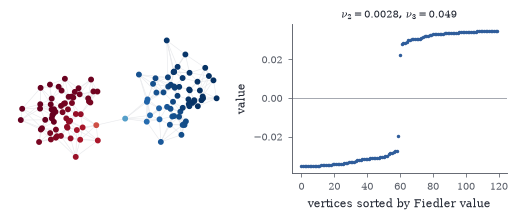

In [2]:
rng = np.random.default_rng(0); n1 = 60; P1 = rng.normal(size=(n1, 2)) * 0.5; P2 = rng.normal(size=(n1, 2)) * 0.5 + [3.2, 0.5]; Pts = np.r_[P1, P2]; n = 2 * n1
D2 = ((Pts[:, None] - Pts[None]) ** 2).sum(-1); Adj = np.zeros((n, n))
for i in range(n):
    for j in np.argsort(D2[i])[1:7]: Adj[i, j] = Adj[j, i] = 1
deg = Adj.sum(1); Lsym = np.eye(n) - Adj / np.sqrt(np.outer(deg, deg)); w, V = np.linalg.eigh(Lsym); fied = V[:, 1] / np.sqrt(deg)
fig, axs = plt.subplots(1, 2, figsize=(W, 1.9))
ii, jj = np.nonzero(np.triu(Adj))
for i, j in zip(ii, jj): axs[0].plot(Pts[[i, j], 0], Pts[[i, j], 1], color=LIGHT, lw=0.4, zorder=0)
sc = axs[0].scatter(Pts[:, 0], Pts[:, 1], c=fied, cmap=CMAP, s=8, zorder=2); axs[0].set_aspect("equal"); axs[0].axis("off")
axs[1].plot(np.sort(fied), ".", color=BLUE, ms=2.5); axs[1].axhline(0, color=GRAY, lw=0.5); axs[1].set_xlabel("vertices sorted by Fiedler value"); axs[1].set_ylabel("value")
axs[1].set_title(rf"$\nu_2={w[1]:.4f}$, $\nu_3={w[2]:.3f}$", fontsize=6.5)

Spectral clustering separates shapes that $k$-means cannot. Left: two interleaving half-moons and a ring, clustered by $k$-means on the raw coordinates (colours are clusters): convex blobs cut across the shapes. Middle: spectral clustering with a $10$-nearest-neighbour graph recovers the three shapes. Right: the smallest eigenvalues of the normalized Laplacian, with a clear gap after the third, which signals three clusters.

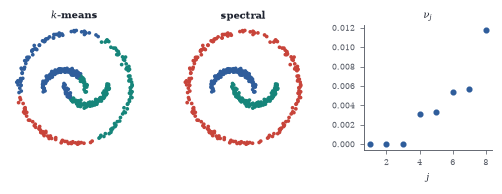

In [3]:
from scipy.cluster.vq import kmeans2
rng = np.random.default_rng(3); t = rng.uniform(0, np.pi, 150)
m1 = np.c_[np.cos(t), np.sin(t)] + rng.normal(0, 0.06, (150, 2)); m2 = np.c_[1 - np.cos(t), 0.4 - np.sin(t)] + rng.normal(0, 0.06, (150, 2))
th = rng.uniform(0, 2 * np.pi, 200); ring = np.c_[0.5 + 2.6 * np.cos(th), 0.2 + 2.6 * np.sin(th)] + rng.normal(0, 0.06, (200, 2)); X = np.r_[m1, m2, ring]; n = len(X)
D2 = ((X[:, None] - X[None]) ** 2).sum(-1); Adj = np.zeros((n, n))
for i in range(n):
    for j in np.argsort(D2[i])[1:11]: Adj[i, j] = Adj[j, i] = 1
deg = Adj.sum(1); Lsym = np.eye(n) - Adj / np.sqrt(np.outer(deg, deg)); w, V = np.linalg.eigh(Lsym); U3 = V[:, :3]; U3 /= np.linalg.norm(U3, axis=1, keepdims=True)
_, lab_sp = kmeans2(U3, 3, seed=1, minit="++"); _, lab_km = kmeans2(X, 3, seed=1, minit="++")
fig, axs = plt.subplots(1, 3, figsize=(W, 1.65), gridspec_kw={"width_ratios": [1, 1, 0.8]})
for ax, lab, ttl in [(axs[0], lab_km, "$k$-means"), (axs[1], lab_sp, "spectral")]:
    ax.scatter(X[:, 0], X[:, 1], c=[PALETTE[l] for l in lab], s=2); ax.set_aspect("equal"); ax.axis("off"); ax.set_title(ttl, fontsize=6.5)
axs[2].plot(np.arange(1, 9), w[:8], "o", color=BLUE, ms=3); axs[2].set_xlabel("$j$", fontsize=6); axs[2].set_title(r"$\nu_j$", fontsize=6.5); axs[2].tick_params(labelsize=5)

Spectral drawings. Vertices placed at their values in the second and third Laplacian eigenvectors. Left: a $12\times12$ grid graph whose vertices were listed in random order; the drawing recovers the grid. Middle: a "dumbbell" of two cliques joined by a path; each clique collapses to nearly a point and the path is stretched out between them. Right: a cycle of $40$ vertices with four random chords; the drawing shows the cycle as a closed loop pulled together where the chords are.

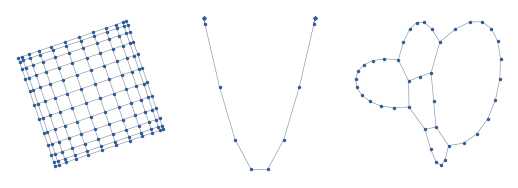

In [4]:
def spectral_draw(ax, Adj):
    Lp = np.diag(Adj.sum(1)) - Adj; w, V = np.linalg.eigh(Lp); P = V[:, 1:3]; ii, jj = np.nonzero(np.triu(Adj))
    for i, j in zip(ii, jj): ax.plot(P[[i, j], 0], P[[i, j], 1], color=GRAY, lw=0.4)
    ax.plot(P[:, 0], P[:, 1], ".", color=BLUE, ms=2.5); ax.set_aspect("equal"); ax.axis("off")
rng = np.random.default_rng(4); k = 12; G = np.zeros((k * k, k * k))
for i in range(k):
    for j in range(k):
        v = i * k + j
        if i + 1 < k: G[v, v + k] = G[v + k, v] = 1
        if j + 1 < k: G[v, v + 1] = G[v + 1, v] = 1
perm = rng.permutation(k * k); G = G[np.ix_(perm, perm)]
c = 10; Db = np.zeros((2 * c + 6, 2 * c + 6)); Db[:c, :c] = 1; Db[c:2 * c, c:2 * c] = 1; np.fill_diagonal(Db, 0); chain = [c - 1] + list(range(2 * c, 2 * c + 6)) + [c]
for a, b in zip(chain[:-1], chain[1:]): Db[a, b] = Db[b, a] = 1
nc = 40; Cy = np.zeros((nc, nc))
for i in range(nc): Cy[i, (i + 1) % nc] = Cy[(i + 1) % nc, i] = 1
for _ in range(4): a, b = rng.choice(nc, 2, replace=False); Cy[a, b] = Cy[b, a] = 1
fig, axs = plt.subplots(1, 3, figsize=(W, 1.6))
for ax, Gm in zip(axs, [G, Db, Cy]): spectral_draw(ax, Gm)

Mixing of random walks. The total variation distance between the walk's distribution after $t$ steps and the stationary distribution, from a single starting vertex, for three graphs on $100$ vertices: a cycle (grey, small spectral gap), two dense clusters joined by one edge (red, a bottleneck), and a random $4$-regular graph (blue, an expander). Dashed lines show $\lambda_*^t$; the decay rate is set by the second eigenvalue. After $400$ steps the cycle and the barbell have barely begun to mix, while the expander is at stationarity to six digits after about $100$.

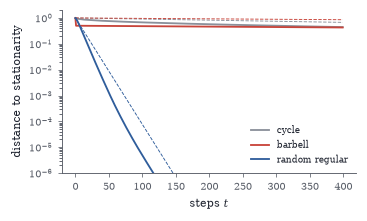

In [5]:
rng = np.random.default_rng(5); n = 100
def lazy_P(Adj): deg = Adj.sum(1); return 0.5 * (np.eye(len(Adj)) + Adj / deg[:, None])
Cyc = np.zeros((n, n))
for i in range(n): Cyc[i, (i + 1) % n] = Cyc[(i + 1) % n, i] = 1
Bar = np.zeros((n, n)); Bar[:50, :50] = 1; Bar[50:, 50:] = 1; np.fill_diagonal(Bar, 0); Bar[0, 50] = Bar[50, 0] = 1
Reg = np.zeros((n, n))
for _ in range(2):
    pm = rng.permutation(n)
    for i in range(n): a, b = pm[i], pm[(i + 1) % n]; Reg[a, b] = Reg[b, a] = 1
fig, ax = plt.subplots(figsize=(W * 0.7, 1.9))
for Adj, col, lab in [(Cyc, GRAY, "cycle"), (Bar, RED, "barbell"), (Reg, BLUE, "random regular")]:
    P = lazy_P(Adj); pi = Adj.sum(1) / Adj.sum(); dist = np.zeros(n); dist[1] = 1; tv = []
    for t in range(400): tv.append(0.5 * np.abs(dist - pi).sum()); dist = dist @ P
    ev = np.sort(np.abs(np.linalg.eigvals(P)))[::-1]; ax.semilogy(tv, color=col, label=lab); ax.semilogy(ev[1] ** np.arange(400), "--", color=col, lw=0.6)
ax.set_ylim(1e-6, 2); ax.set_xlabel("steps $t$"); ax.set_ylabel("distance to stationarity"); ax.legend(fontsize=6)

In [6]:
Ad = np.zeros((4, 4)); Ad[0, 1] = Ad[0, 2] = Ad[1, 2] = Ad[2, 0] = Ad[3, 2] = 1; P = Ad / Ad.sum(1, keepdims=True); al = 0.85; nn = 4
G = al * P + (1 - al) / nn; pi = np.full(nn, 1 / nn)
for _ in range(100): pi = pi @ G
pi_lin = (1 - al) / nn * np.linalg.solve((np.eye(nn) - al * P).T, np.ones(nn))
print("power method:", np.round(pi, 4), "  linear system:", np.round(pi_lin / pi_lin.sum(), 4))

power method: [0.3725 0.1958 0.3941 0.0375]   linear system: [0.3725 0.1958 0.3941 0.0375]


In [7]:
def reff(Adj, a, b):
    L = np.diag(Adj.sum(1)) - Adj; e = np.zeros(len(Adj)); e[a], e[b] = 1, -1; return e @ np.linalg.pinv(L) @ e
Pk = np.diag(np.ones(4), 1); Pk = Pk + Pk.T; C4 = np.array([[0, 1, 0, 1], [1, 0, 1, 0], [0, 1, 0, 1], [1, 0, 1, 0.]])
print("path of 4 edges:", round(reff(Pk, 0, 4), 6), "   4-cycle, opposite vertices:", round(reff(C4, 0, 2), 6))

path of 4 edges: 4.0    4-cycle, opposite vertices: 1.0


In [8]:
rng = np.random.default_rng(6); Ap = rng.uniform(0.1, 1, (6, 6)); ev, Vv = np.linalg.eig(Ap); k = np.argmax(np.abs(ev)); v = Vv[:, k].real; v /= v.sum()
print("dominant eigenvalue:", np.round(ev[k], 6), "  eigenvector:", np.round(v, 4), "  next modulus:", np.round(np.sort(np.abs(ev))[-2], 4))

dominant eigenvalue: (3.246737+0j)   eigenvector: [0.1819 0.159  0.1575 0.1586 0.1638 0.1791]   next modulus: 0.7957
